<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="310" alt="Query.Farm Strata Sun and wordmark"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" width="115" alt="VGI logo"></a>

# What falls inside a reported maturity window?

A holdings list gives a row to a small position and a large position alike. For **JPST**, how much of the returned list has a reported maturity date within the next year—and does counting rows tell the same story as adding reported weights? We will preserve missing dates, inspect the security types behind the result, and widen the window in one experiment.

This notebook calls the real J.P. Morgan worker through Haybarn/VGI and retrieves **live current** issuer data. The saved outputs show one retrieval, not a historical query. The worker’s `maturity_date` prefers the issuer’s **final legal maturity date**, falling back to its **WAM maturity date**; it does not expose which field supplied each row. The resulting date profile is descriptive: it is not duration, a repayment forecast, a liquidity estimate, or an investment recommendation.

## Choose a window

`HORIZON_DAYS` is a whole number of calendar days, accepted from 30 through 1,095. Each row is measured from its own returned holdings `as_of_date`, **including both day 0 and day HORIZON_DAYS**. Earlier dates, later dates, and missing dates are separate categories. Restart and run all after editing. No wall-clock date is substituted for an issuer date.

In [1]:
HORIZON_DAYS = 365  # Calendar days after the returned holdings date; experiment: 730.

In [2]:
from datetime import UTC, datetime

import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

from notebook_support import COLORS, finish, prose, theme

if type(HORIZON_DAYS) is not int or not 30 <= HORIZON_DAYS <= 1095:
    raise ValueError("HORIZON_DAYS must be an integer from 30 through 1095.")
retrieved_utc = datetime.now(UTC).isoformat(timespec="seconds")
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%sql connection

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-etf-jpmorgan/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-etf-jpmorgan/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-etf-jpmorgan/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-etf-jpmorgan/notebooks/pyproject.toml.

## Connect and retain one retrieval of each object

The pinned native release downloads automatically. The selected fund partition keeps the holdings request bounded. Separate `CREATE TABLE` statements materialize remote calls before local captures, so displaying a result does not repeat retrieval. Catalog, details, and holdings responses are separate requests rather than an atomic snapshot.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'jpmorgan' AS jpm (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-etf-jpmorgan@v0.4.0');
CREATE TABLE product AS SELECT * FROM jpm.main.products WHERE ticker = 'JPST';
CREATE TABLE details AS SELECT * FROM jpm.main.fund_details('JPST');
CREATE TABLE holdings AS SELECT * FROM jpm.main.holdings WHERE fund_ticker = 'JPST';

1 rows affected.

1 rows affected.

812 rows affected.

,Count


## Establish coverage before calculating a share

The details snapshot’s `num_holdings` is shown next to the number of returned rows; they are distinct source quantities and need not agree. The worker prefers `dailyHoldingsAll`, with a top-list fallback when that block is absent. More than ten rows rules out only a ten-row response, not every possible source omission. The following diagnostics describe the **returned list**. We retain signed net weights and count missing weights and dates explicitly.

In [4]:
%%sql availability <<
SELECT p.ticker, p.name, p.nav_date AS catalog_nav_date,
       d.as_of_date AS details_date, d.num_holdings AS details_reported_holdings,
       h.* EXCLUDE (join_key)
FROM product p JOIN details d USING (ticker)
CROSS JOIN (
    SELECT 1 AS join_key, count(*) AS returned_rows, count(DISTINCT as_of_date) AS holdings_dates,
           min(as_of_date) AS holdings_date,
           count(*) FILTER (WHERE as_of_date IS NULL) AS missing_as_of,
           count(*) FILTER (WHERE maturity_date IS NULL) AS missing_maturity,
           count(*) FILTER (WHERE weight_percent IS NULL) AS missing_weight,
           count(*) FILTER (WHERE weight_percent > 0) AS positive_rows,
           count(*) FILTER (WHERE weight_percent = 0) AS zero_rows,
           count(*) FILTER (WHERE weight_percent < 0) AS negative_rows,
           sum(weight_percent) AS net_weight_percent,
           sum(CASE WHEN weight_percent > 0 THEN weight_percent ELSE 0 END) AS positive_weight_percent,
           sum(CASE WHEN weight_percent < 0 THEN weight_percent ELSE 0 END) AS negative_weight_percent
    FROM holdings
) h;

In [5]:
display(availability)
assert len(availability) == 1, "Expected one JPST catalog/details match; inspect source availability."
a = availability.iloc[0]
prose(
    f"Retrieval started at **{retrieved_utc}**. The holdings date is **{a.holdings_date:%Y-%m-%d}**. "
    f"The returned list contains **{int(a.returned_rows):,} rows**, while the separate details snapshot reports "
    f"**{int(a.details_reported_holdings):,} holdings**. "
    "We do not force those counts to match or infer why they differ. "
    f"**{int(a.missing_maturity)} rows** have no reported maturity date; "
    f"the net signed weight totals **{a.net_weight_percent:.2f}%**. "
    "Published rounding can prevent exact agreement with 100%; no rescaling is applied to that diagnostic."
)

,ticker,name,catalog_nav_date,details_date,details_reported_holdings,returned_rows,holdings_dates,holdings_date,missing_as_of,missing_maturity,missing_weight,positive_rows,zero_rows,negative_rows,net_weight_percent,positive_weight_percent,negative_weight_percent
0,JPST,JPMorgan Ultra-Short Income ETF,2026-11-13,2026-11-13,809,812,1,2026-11-13,0,5,0,784,28,0,99.87,99.87,0.0


Retrieval started at **2026-11-14T06:31:12+00:00**. The holdings date is **2026-11-13**. The returned list contains **812 rows**, while the separate details snapshot reports **809 holdings**. We do not force those counts to match or infer why they differ. **5 rows** have no reported maturity date; the net signed weight totals **99.87%**. Published rounding can prevent exact agreement with 100%; no rescaling is applied to that diagnostic.

In [6]:
%%sql source_checks <<
SELECT 'one populated dated holdings response' AS check_name,
       count(*) > 10 AND count(DISTINCT as_of_date) = 1 AND count(as_of_date) = count(*) AS passed FROM holdings
UNION ALL SELECT 'only requested fund', bool_and(fund_ticker = 'JPST') FROM holdings
UNION ALL SELECT 'complete finite reported weights',
       count(weight_percent) = count(*) AND bool_and(isfinite(weight_percent)) FROM holdings
UNION ALL SELECT 'positive weight denominator exists', sum(CASE WHEN weight_percent > 0 THEN weight_percent ELSE 0 END) > 0
FROM holdings
UNION ALL SELECT 'holding rank key unique',
       count(*) = count(DISTINCT (fund_ticker, holding_rank)) AND count(holding_rank) = count(*) FROM holdings
UNION ALL SELECT 'signed weights reconcile',
       abs(sum(weight_percent) - sum(CASE WHEN weight_percent > 0 THEN weight_percent ELSE 0 END)
           - sum(CASE WHEN weight_percent < 0 THEN weight_percent ELSE 0 END)) < 1e-8 FROM holdings;

In [7]:
display(source_checks)
assert source_checks.passed.fillna(False).all(), "Required source coverage failed; inspect diagnostics."

,check_name,passed
0,one populated dated holdings response,True
1,only requested fund,True
2,complete finite reported weights,True
3,positive weight denominator exists,True
4,holding rank key unique,True
5,signed weights reconcile,True


## Classify dates without turning missing into zero

The SQL assigns every row to exactly one category. Row shares use **all returned rows** as their denominator. Weight shares use **the sum of positive reported weights** across those rows, including positive weights whose date is missing. Negative and zero weights remain in diagnostics but contribute no positive weight. `weight_percent` already uses percentage points; there is no extra ×100 conversion before summing. Missing dates are never treated as maturing today.

In [8]:
%%sql
CREATE TABLE classified AS
SELECT *, date_diff('day', as_of_date, maturity_date) AS days_from_holdings,
       CASE WHEN maturity_date IS NULL THEN 3
            WHEN maturity_date < as_of_date THEN 0
            WHEN date_diff('day', as_of_date, maturity_date) <= {{HORIZON_DAYS}} THEN 1
            ELSE 2 END AS bucket_id,
       CASE WHEN weight_percent > 0 THEN weight_percent ELSE 0 END AS positive_weight,
       coalesce(nullif(sec_type, ''), 'UNREPORTED SECURITY TYPE') AS security_type
FROM holdings;
CREATE TABLE buckets AS
WITH definitions(bucket_id, label) AS (VALUES
 (0, 'Earlier than holdings date'), (1, 'Day 0 through ' || {{HORIZON_DAYS}}::VARCHAR),
 (2, 'After day ' || {{HORIZON_DAYS}}::VARCHAR), (3, 'Maturity date missing')),
 totals AS (SELECT count(*) AS n, sum(positive_weight) AS weight FROM classified)
SELECT b.bucket_id, b.label, count(c.holding_rank) AS rows,
       coalesce(sum(c.positive_weight), 0) AS positive_weight_percent,
       100.0 * count(c.holding_rank) / t.n AS row_share_percent,
       100.0 * coalesce(sum(c.positive_weight), 0) / t.weight AS positive_share_percent
FROM definitions b CROSS JOIN totals t LEFT JOIN classified c USING (bucket_id)
GROUP BY b.bucket_id, b.label, t.n, t.weight;

812 rows affected.

4 rows affected.

,Count


In [9]:
%%sql buckets <<
SELECT * FROM buckets ORDER BY bucket_id;

In [10]:
display(buckets)

,bucket_id,label,rows,positive_weight_percent,row_share_percent,positive_share_percent
0,0,Earlier than holdings date,0,0.00,0.000000,0.000000
1,1,Day 0 through 365,323,41.62,39.778325,41.674176
2,2,After day 365,484,54.80,59.605911,54.871333
3,3,Maturity date missing,5,3.45,0.615764,3.454491


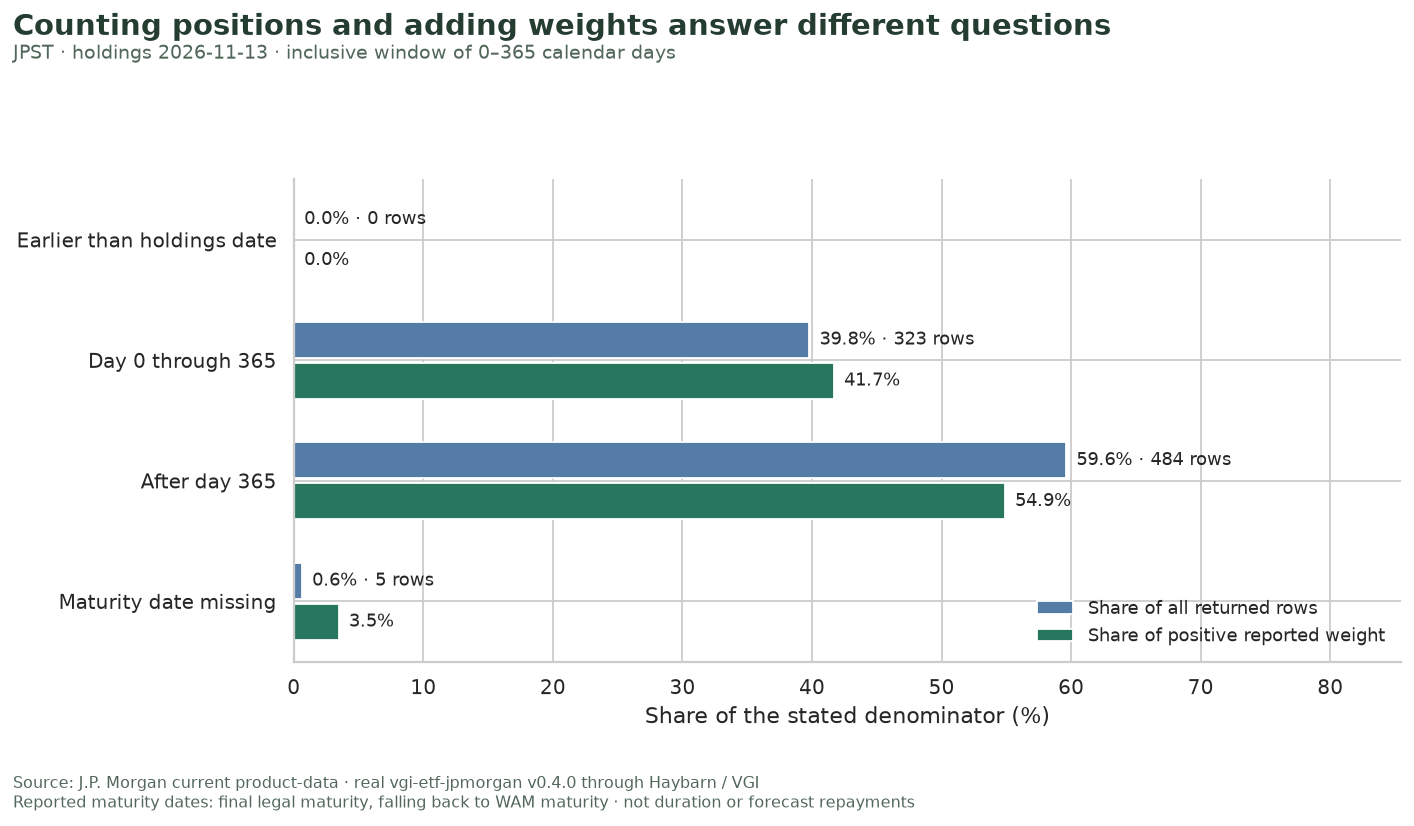

In [11]:
fig, ax = plt.subplots(figsize=(12, 6.4))
y = np.arange(len(buckets))
ax.barh(y - 0.17, buckets.row_share_percent, height=0.30, color="#557ca6", label="Share of all returned rows")
ax.barh(
    y + 0.17, buckets.positive_share_percent, height=0.30, color="#27765d", label="Share of positive reported weight"
)
for i, row in enumerate(buckets.itertuples()):
    ax.text(
        row.row_share_percent + 0.8,
        i - 0.17,
        f"{row.row_share_percent:.1f}% · {row.rows} rows",
        va="center",
        fontsize=10,
    )
    ax.text(row.positive_share_percent + 0.8, i + 0.17, f"{row.positive_share_percent:.1f}%", va="center", fontsize=10)
ax.set_yticks(y, buckets.label)
ax.invert_yaxis()
ax.set_xlim(0, max(buckets.row_share_percent.max(), buckets.positive_share_percent.max()) * 1.30 + 8)
ax.set_xlabel("Share of the stated denominator (%)")
ax.legend(loc="lower right", frameon=False, fontsize=10)
fig.subplots_adjust(left=0.25, right=0.96, bottom=0.20, top=0.78)
finish(
    fig,
    "Counting positions and adding weights answer different questions",
    f"JPST · holdings {a.holdings_date:%Y-%m-%d} · inclusive window of 0–{HORIZON_DAYS} calendar days",
    f"coverage-{HORIZON_DAYS}.png",
)

In [12]:
inside = buckets.loc[buckets.bucket_id == 1].iloc[0]
missing = buckets.loc[buckets.bucket_id == 3].iloc[0]
prose(
    f"The 0–{HORIZON_DAYS}-day category contains **{int(inside.rows):,} rows** "
    f"(**{inside.row_share_percent:.1f}%** of the list) and **{inside.positive_share_percent:.1f}%** "
    "of positive reported weight. "
    f"Missing maturity dates retain **{missing.positive_share_percent:.1f}%** of that same weight denominator. "
    "Dropping them would silently change the denominator. The next query shows which security types contribute "
    "to each category without interpreting a later legal date as a duration estimate."
)

The 0–365-day category contains **323 rows** (**39.8%** of the list) and **41.7%** of positive reported weight. Missing maturity dates retain **3.5%** of that same weight denominator. Dropping them would silently change the denominator. The next query shows which security types contribute to each category without interpreting a later legal date as a duration estimate.

## Identify the security types behind the date profile

This is a decomposition of the same positive-weight total, using the issuer’s returned security-type labels. Every segment is a share of the **whole returned list’s positive weight**, not a percentage within its security type. The grouped table retains row counts and missing-date counts for inspection.

In [13]:
%%sql types <<
SELECT security_type, bucket_id, count(*) AS rows,
       count(*) FILTER (WHERE maturity_date IS NULL) AS missing_maturity,
       sum(positive_weight) AS positive_weight_percent,
       100.0 * sum(positive_weight) / (SELECT sum(positive_weight) FROM classified) AS positive_share_percent
FROM classified GROUP BY security_type, bucket_id ORDER BY security_type, bucket_id;

In [14]:
display(types)

,security_type,bucket_id,rows,missing_maturity,positive_weight_percent,positive_share_percent
0,AGENCY BACKED BONDS,2,1,0,0.11,0.110143
1,ASSET BACKED,1,2,0,0.02,0.020026
2,ASSET BACKED,2,111,0,9.87,9.882848
3,CDO/COLLATERALIZED DEBT OBLIGATION,2,68,0,6.04,6.047862
4,CERTIFICATE OF DEPOSIT,1,27,0,5.16,5.166717
5,CMO/REMIC,1,2,0,0.52,0.520677
6,COMMERCIAL PAPER,1,92,0,18.89,18.914589
7,CORPORATE BONDS,1,196,0,16.36,16.381296
8,CORPORATE BONDS,2,303,0,36.68,36.727746
9,CURRENCIES,3,3,3,2.25,2.252929


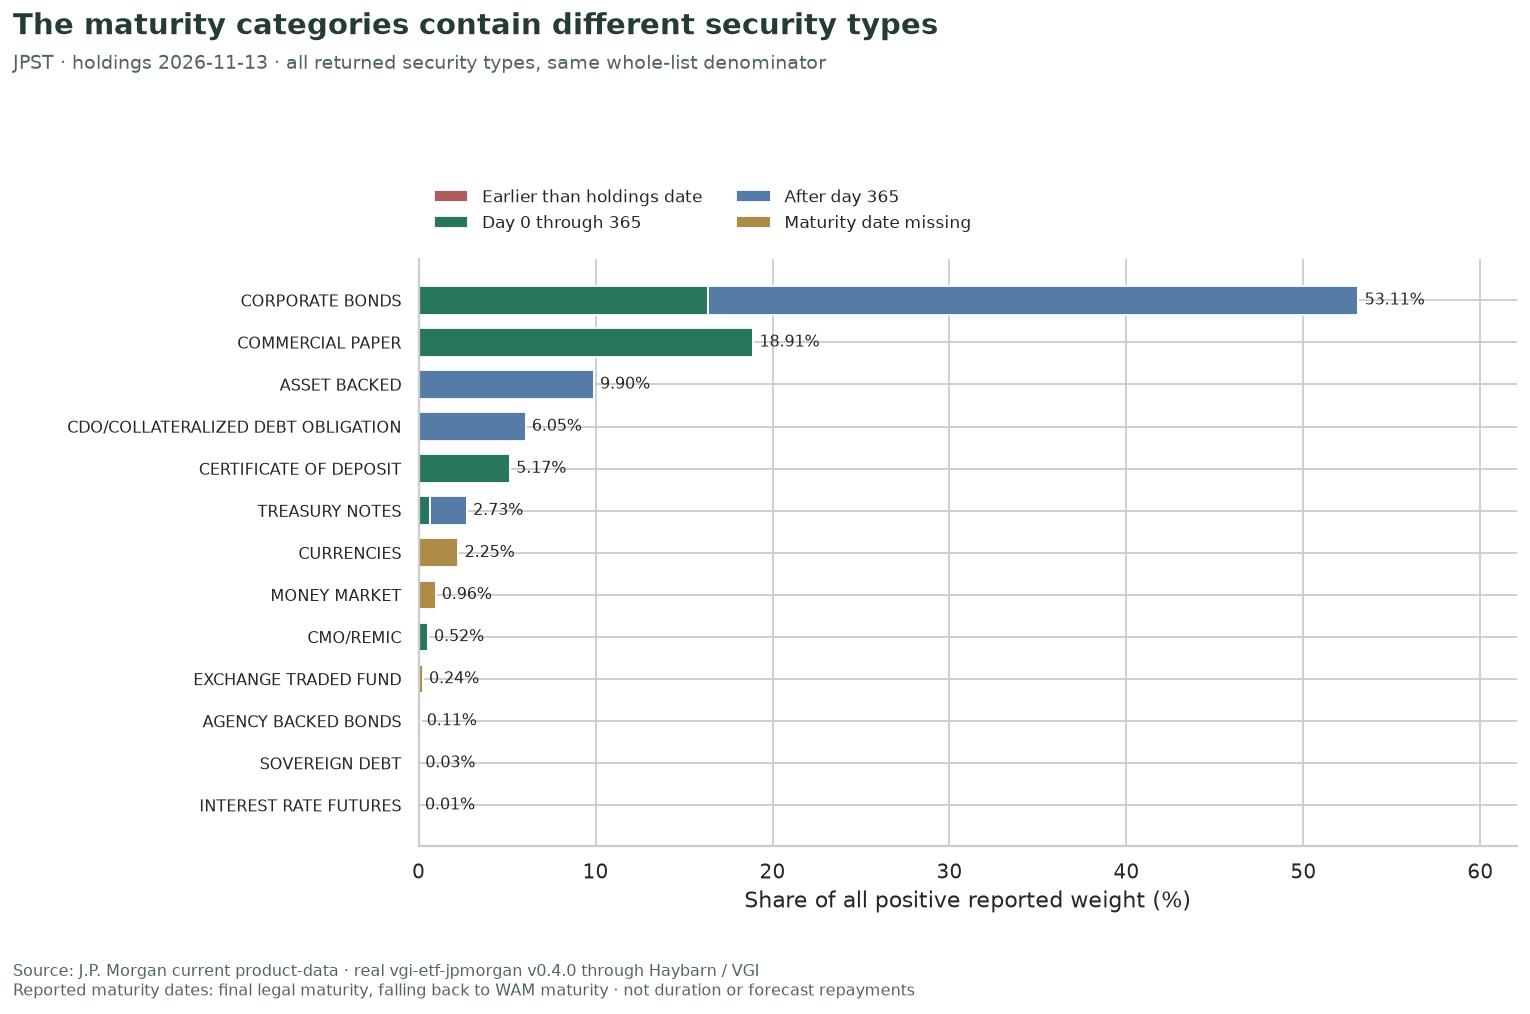

In [15]:
matrix = types.pivot(index="security_type", columns="bucket_id", values="positive_share_percent").fillna(0)
matrix = matrix.reindex(columns=[0, 1, 2, 3], fill_value=0)
matrix = matrix.loc[matrix.sum(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(13, max(7.5, len(matrix) * 0.34 + 3.5)))
left = np.zeros(len(matrix))
for bucket in buckets.itertuples():
    values = matrix[bucket.bucket_id].to_numpy()
    ax.barh(np.arange(len(matrix)), values, left=left, color=COLORS[bucket.bucket_id], label=bucket.label, height=0.68)
    left += values
for i, total in enumerate(left):
    ax.text(total + 0.35, i, f"{total:.2f}%", va="center", fontsize=9)
ax.set_yticks(np.arange(len(matrix)), matrix.index, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, max(left) * 1.15 + 1)
ax.set_xlabel("Share of all positive reported weight (%)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncols=2, frameon=False, fontsize=9.5)
fig.subplots_adjust(left=0.31, right=0.96, bottom=0.17, top=0.74)
finish(
    fig,
    "The maturity categories contain different security types",
    f"JPST · holdings {a.holdings_date:%Y-%m-%d} · all returned security types, same whole-list denominator",
    f"types-{HORIZON_DAYS}.png",
)

## Check that every contribution is accounted for

The categories must partition the returned rows, both shares must sum to 100%, and the security-type decomposition must reproduce each category’s weight. These arithmetic checks do not establish that an issuer response is complete or that its maturity fields describe comparable economic terms.

In [16]:
%%sql arithmetic_checks <<
SELECT 'categories retain every row' AS check_name,
       (SELECT sum(rows) FROM buckets) = (SELECT count(*) FROM holdings) AS passed
UNION ALL SELECT 'row and positive-weight shares each total 100',
       abs(sum(row_share_percent) - 100) < 1e-8 AND abs(sum(positive_share_percent) - 100) < 1e-8 FROM buckets
UNION ALL SELECT 'all dated rows obey their category boundaries',
       bool_and((bucket_id = 0 AND days_from_holdings < 0)
                OR (bucket_id = 1 AND days_from_holdings BETWEEN 0 AND {{HORIZON_DAYS}})
                OR (bucket_id = 2 AND days_from_holdings > {{HORIZON_DAYS}})
                OR (bucket_id = 3 AND maturity_date IS NULL)) FROM classified
UNION ALL SELECT 'security types reconcile category weights', bool_and(abs(b.positive_weight_percent - coalesce(t.w, 0)) < 1e-8)
FROM buckets b LEFT JOIN (SELECT bucket_id, sum(positive_weight) w FROM classified GROUP BY bucket_id) t USING (bucket_id);

In [17]:
display(arithmetic_checks)
assert arithmetic_checks.passed.fillna(False).all(), "Date-profile accounting failed."
prose(
    f"All **{len(source_checks) + len(arithmetic_checks)} source and arithmetic checks** pass. "
    "The conclusion is limited to the returned date fields and reported weights; "
    "it does not supply cash-flow timing, effective duration, or the missing maturity dates."
)

,check_name,passed
0,categories retain every row,True
1,row and positive-weight shares each total 100,True
2,all dated rows obey their category boundaries,True
3,security types reconcile category weights,True


All **10 source and arithmetic checks** pass. The conclusion is limited to the returned date fields and reported weights; it does not supply cash-flow timing, effective duration, or the missing maturity dates.

## Experiment: widen only the date window

Change **`HORIZON_DAYS = 365` to `730`**, restart and run all, and compare the within-window row and weight shares. For unchanged input, the 0–730-day category must contain the 0–365-day category; its counts and positive weight cannot fall. Missing-date rows and weights should stay unchanged. Look at the security-type segments to see where the added weight came from. Restore **365** for the default.

Each fresh execution retrieves current data again. Compare source dates and diagnostics before attributing changes to the parameter; same-date issuer revisions can also occur. See the README for a separate-output command. Expanding this date window still does not transform mixed reported maturity dates into a repayment or interest-rate-risk model.

In [18]:
connection.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="310" alt="Query.Farm Strata Sun and wordmark"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · Source: [J.P. Morgan JPST](https://am.jpmorgan.com/us/en/asset-management/adv/products/jpmorgan-ultra-short-income-etf-etf-shares-46641q837)